# bao.ipynb — Phân lớp KNN và SVM

**Bài tập lớn Khai thác dữ liệu: Dry Bean Dataset**

- Đây là **khung Notebook**, chưa có dữ liệu hoặc kết quả huấn luyện.
- Mỗi thành viên làm trên nhánh riêng **`bao-brand`** do tự tạo sau này; hiện chỉ có nhánh `main` được cập nhật.
- Lưu minh chứng vào `outputs/`, giải thích mọi biểu đồ và chỉ đưa kết quả chạy thật vào báo cáo.
- Nếu dùng Google Colab, bảo đảm dữ liệu được tải lên đúng đường dẫn hoặc chỉnh `ROOT`.


## 0. Thiết lập thư mục và môi trường

Chạy cell dưới đây để xác định đường dẫn; thư mục dữ liệu nguồn chưa có file trong repository.

In [1]:
# Khoi tao du an: thay doi ROOT neu chay notebook tu vi tri khac
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "outputs" / "figures"
TABLES_DIR = ROOT / "outputs" / "tables"
print("Project root:", ROOT)
# TODO: khi co dataset, bo sung cac imports va doc tep can thiet.


Project root: c:\Users\dinhg\Khai_Thac_Du_Lieu_Gr6


In [2]:
import pandas as pd

In [3]:
# 1. Đọc dữ liệu CSV chung của nhóm

file_path = PROCESSED_DIR / "dry_bean.csv"

if file_path.exists():
    print("Đã tìm thấy dataset:", file_path)

    df = pd.read_csv(file_path)

    print("Dung lượng:", round(file_path.stat().st_size / 1024 / 1024, 2), "MB")
    display(df.head())

else:
    raise FileNotFoundError(f"Không tìm thấy dataset: {file_path}")

Đã tìm thấy dataset: c:\Users\dinhg\Khai_Thac_Du_Lieu_Gr6\data\processed\dry_bean.csv
Dung lượng: 3.65 MB


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 06. Thiết kế bộ train/test và CV






In [4]:
# 2. Kiểm tra và khám phá dữ liệu

print("Kích thước dữ liệu:", df.shape)
print("Danh sách cột:", df.columns.tolist())

# Kiểm tra dữ liệu thiếu
print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum().sum())

# 3. Tách đặc trưng X và nhãn y
X = df.drop(columns=["Class"])
y = df["Class"]

print("\nKích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nSố lớp phân loại:", y.nunique())

print("\nPhân bố các lớp:")
print(y.value_counts())

Kích thước dữ liệu: (13611, 17)
Danh sách cột: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Số lượng giá trị thiếu:
0

Kích thước X: (13611, 16)
Kích thước y: (13611,)

Số lớp phân loại: 7

Phân bố các lớp:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [5]:

# 1. Đọc bộ dữ liệu Train/Test dùng chung của nhóm
train_path = PROCESSED_DIR / "train.csv"
test_path = PROCESSED_DIR / "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# 2. Tách đặc trưng X và nhãn y
X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"]

# 3. Kiểm tra kích thước dữ liệu
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

# 4. Kiểm tra phân bố các lớp
print("\nPhân bố lớp trong Train:")
print(y_train.value_counts().sort_index())

print("\nPhân bố lớp trong Test:")
print(y_test.value_counts().sort_index())


Kích thước X_train: (10888, 16)
Kích thước X_test: (2723, 16)
Kích thước y_train: (10888,)
Kích thước y_test: (2723,)

Phân bố lớp trong Train:
Class
BARBUNYA    1057
BOMBAY       418
CALI        1304
DERMASON    2837
HOROZ       1542
SEKER       1621
SIRA        2109
Name: count, dtype: int64

Phân bố lớp trong Test:
Class
BARBUNYA    265
BOMBAY      104
CALI        326
DERMASON    709
HOROZ       386
SEKER       406
SIRA        527
Name: count, dtype: int64


In [6]:
# Lưu tập Train và Test
import pandas as pd

SPLIT_DIR = ROOT / "data" / "processed"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.concat([
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True).rename("Class")
], axis=1)

test_df = pd.concat([
    X_test.reset_index(drop=True),
    y_test.reset_index(drop=True).rename("Class")
], axis=1)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Đã lưu Train:", train_df.shape)
print("Đã lưu Test:", test_df.shape)

Đã lưu Train: (10888, 17)
Đã lưu Test: (2723, 17)


In [7]:
from sklearn.model_selection import StratifiedKFold

# Thiết lập 10-fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

print("Số lượng Fold:", cv.get_n_splits())
print("Phương pháp: StratifiedKFold")
print("Shuffle: True")
print("Random State: 42")

Số lượng Fold: 10
Phương pháp: StratifiedKFold
Shuffle: True
Random State: 42


In [8]:
# Kiểm tra kích thước từng Fold
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Fold 1: Train = 9799, Validation = 1089
Fold 2: Train = 9799, Validation = 1089
Fold 3: Train = 9799, Validation = 1089
Fold 4: Train = 9799, Validation = 1089
Fold 5: Train = 9799, Validation = 1089
Fold 6: Train = 9799, Validation = 1089
Fold 7: Train = 9799, Validation = 1089
Fold 8: Train = 9799, Validation = 1089
Fold 9: Train = 9800, Validation = 1088
Fold 10: Train = 9800, Validation = 1088


In [9]:
# Kiểm tra tỷ lệ 7 lớp trong từng Fold
fold_distribution = []

for fold, (_, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    y_val = y_train.iloc[val_idx]

    proportions = y_val.value_counts(normalize=True)
    proportions.name = f"Fold {fold}"

    fold_distribution.append(proportions)

# Tạo bảng so sánh
fold_df = pd.DataFrame(fold_distribution)

display(fold_df.round(4))

Class,DERMASON,SIRA,SEKER,HOROZ,CALI,BARBUNYA,BOMBAY
Fold 1,0.2608,0.1938,0.1497,0.1414,0.1194,0.0964,0.0386
Fold 2,0.2608,0.1938,0.1488,0.1423,0.1194,0.0964,0.0386
Fold 3,0.2608,0.1938,0.1488,0.1423,0.1194,0.0964,0.0386
Fold 4,0.2599,0.1938,0.1488,0.1414,0.1203,0.0973,0.0386
Fold 5,0.2599,0.1938,0.1488,0.1414,0.1203,0.0973,0.0386
Fold 6,0.2599,0.1938,0.1488,0.1414,0.1203,0.0973,0.0386
Fold 7,0.2608,0.1928,0.1488,0.1414,0.1203,0.0973,0.0386
Fold 8,0.2608,0.1938,0.1488,0.1414,0.1194,0.0973,0.0386
Fold 9,0.2610,0.1939,0.1489,0.1415,0.1195,0.0974,0.0377
Fold 10,0.2610,0.1939,0.1489,0.1415,0.1195,0.0974,0.0377



### 1. Mục tiêu và kiến thức liên quan

Mục tiêu của phần này là xây dựng quy trình chia dữ liệu hợp lý để phục vụ huấn luyện và đánh giá mô hình Machine Learning trên bộ dữ liệu Dry Bean.

Dữ liệu gồm 13.611 mẫu, 16 thuộc tính đầu vào và 7 lớp phân loại.

Các kỹ thuật được sử dụng:
- Train/Test Split.
- Stratified Sampling.
- StratifiedKFold Cross Validation.
- Random State.
- F1-macro.

### 2. Phương pháp và tham số lựa chọn

Nhóm sử dụng train_test_split để chia dữ liệu theo tỷ lệ 80% Train và 20% Test.

Các tham số:
- test_size = 0.2
- random_state = 42
- stratify = y

Tiếp theo, sử dụng StratifiedKFold với 10 Fold, shuffle=True và random_state=42 để đánh giá mô hình ổn định hơn.

Stratify giúp duy trì tỷ lệ các lớp trong từng tập dữ liệu, hạn chế tình trạng mất cân bằng khi chia dữ liệu.

### 3. Kết quả thực nghiệm

Kết quả chia dữ liệu:
- Train: 10.888 mẫu.
- Test: 2.723 mẫu.

Quá trình Cross Validation tạo thành 10 Fold:
- Mỗi Fold có khoảng 9.799–9.800 mẫu huấn luyện.
- Mỗi Fold có khoảng 1.088–1.089 mẫu validation.

Kết quả kiểm tra phân bố cho thấy tỷ lệ 7 lớp giữa các Fold tương đối đồng đều.

### 4. Nhận xét và hạn chế

Việc sử dụng StratifiedKFold giúp các Fold duy trì tỷ lệ phân bố lớp tương đối ổn định, hỗ trợ đánh giá mô hình khách quan hơn.

Random State giúp tái lập kết quả thực nghiệm.

Hạn chế: Quá trình chia dữ liệu và Cross Validation chưa phản ánh trực tiếp hiệu suất mô hình. Cần kết hợp Pipeline, GridSearchCV và F1-macro ở bước huấn luyện KNN và SVM để đánh giá hiệu quả phân loại.

# 07. K-NEAREST NEIGHBORS (KNN)

## 1. Giới thiệu thuật toán KNN

K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát (Supervised Learning), được sử dụng trong các bài toán phân loại (Classification) và hồi quy (Regression).

KNN dự đoán nhãn của một mẫu dữ liệu mới dựa trên K mẫu dữ liệu gần nhất trong tập huấn luyện.

Trong dự án Dry Bean Dataset, KNN được sử dụng để phân loại 7 loại hạt đậu dựa trên 16 thuộc tính hình dạng và kích thước.

## 2. Nguyên lý hoạt động

1. Chọn số lượng láng giềng K.
2. Tính khoảng cách từ mẫu cần dự đoán đến các mẫu trong tập huấn luyện.
3. Sắp xếp khoảng cách theo thứ tự tăng dần.
4. Chọn K mẫu gần nhất.
5. Xác định nhãn dự đoán dựa trên kết quả bỏ phiếu của các láng giềng.

## 3. Các tham số quan trọng

- n_neighbors (K): Số lượng láng giềng được sử dụng để dự đoán.
- weights: Cách tính trọng số cho các láng giềng.
- metric: Phương pháp tính khoảng cách.
- p: Tham số của khoảng cách Minkowski.

## 4. Chuẩn hóa dữ liệu bằng StandardScaler

KNN là thuật toán dựa trên khoảng cách. Nếu các thuộc tính có thang đo khác nhau, thuộc tính có giá trị lớn có thể chi phối kết quả tính khoảng cách.

StandardScaler đưa dữ liệu về trung bình gần 0 và độ lệch chuẩn gần 1.

Việc chuẩn hóa giúp các thuộc tính đóng góp cân bằng hơn vào khoảng cách giữa các mẫu.

## 5. Khoảng cách Euclidean

Khoảng cách Euclidean giữa hai điểm được tính theo công thức:

d(x,y) = sqrt(sum((x_i - y_i)^2))

Khoảng cách càng nhỏ thì hai mẫu dữ liệu càng gần nhau.

## 6. Ưu điểm và hạn chế

### Ưu điểm
- Dễ hiểu và dễ triển khai.
- Không yêu cầu quá trình huấn luyện phức tạp.
- Có thể giải quyết bài toán phân loại nhiều lớp.

### Hạn chế
- Tốn chi phí tính toán khi dữ liệu lớn.
- Nhạy cảm với thang đo thuộc tính.
- Kết quả phụ thuộc vào lựa chọn K và metric.
- Có thể bị ảnh hưởng bởi nhiễu và thuộc tính không liên quan.
## 7. Giải thích các tham số trong mô hình KNN

### 7.1. n_neighbors (K)

Đây là số lượng láng giềng gần nhất được sử dụng để dự đoán nhãn của một mẫu mới.

- K nhỏ: Mô hình nhạy với nhiễu và dễ Overfitting.
- K lớn: Mô hình ổn định hơn nhưng có thể Underfitting.

Trong dự án, K sẽ được lựa chọn thông qua GridSearchCV thay vì chọn tùy ý.

### 7.2. weights

Tham số weights xác định cách tính trọng số cho các láng giềng:

- uniform: Tất cả láng giềng có trọng số như nhau.
- distance: Láng giềng càng gần thì có trọng số càng lớn.

Hai phương pháp sẽ được thử nghiệm để tìm ra lựa chọn phù hợp.

### 7.3. metric

Là phương pháp đo khoảng cách giữa các mẫu dữ liệu.

Dự án sử dụng khoảng cách Minkowski, cho phép lựa chọn các dạng khoảng cách khác nhau thông qua tham số p.

### 7.4. Lý do sử dụng GridSearchCV

GridSearchCV giúp thử nghiệm nhiều tổ hợp tham số KNN và đánh giá bằng Cross Validation.

Tiêu chí lựa chọn mô hình là F1-macro trung bình trên 10 Fold.

Nhờ đó, có thể tìm được bộ tham số phù hợp với bài toán phân loại 7 loại hạt đậu.

In [10]:

# ============================================================
# 07. KNN - Pipeline + GridSearchCV + Stratified 10-Fold
# ============================================================

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Khởi tạo Stratified 10-Fold
cv_knn = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# 2. Xây dựng Pipeline
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# 3. Xây dựng lưới tham số
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['minkowski'],
    'knn__p': [1, 2]
}

# 4. GridSearchCV với tiêu chí F1-macro
grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring='f1_macro',
    cv=cv_knn,
    n_jobs=-1,
    verbose=1
)

# 5. Huấn luyện trên tập Train
grid_knn.fit(X_train, y_train)

# 6. Lấy mô hình tốt nhất
best_knn = grid_knn.best_estimator_

print("===== KẾT QUẢ TỐI ƯU KNN =====")
print("Best parameters:", grid_knn.best_params_)
print("Best CV F1-macro:", round(grid_knn.best_score_, 4))

# 7. Đánh giá trên tập Test
y_pred_knn = best_knn.predict(X_test)

print("\n===== ĐÁNH GIÁ TRÊN TEST =====")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))
print("F1-macro:", round(f1_score(
    y_test, y_pred_knn, average='macro'
), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

# 8. Ma trận nhầm lẫn
cm_knn = confusion_matrix(y_test, y_pred_knn)

cm_knn_df = pd.DataFrame(
    cm_knn,
    index=best_knn.classes_,
    columns=best_knn.classes_
)

display(cm_knn_df)


Fitting 10 folds for each of 28 candidates, totalling 280 fits
===== KẾT QUẢ TỐI ƯU KNN =====
Best parameters: {'knn__metric': 'minkowski', 'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'distance'}
Best CV F1-macro: 0.9379

===== ĐÁNH GIÁ TRÊN TEST =====
Accuracy: 0.9188
F1-macro: 0.9323

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.97      0.88      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.91      0.90      0.91       709
       HOROZ       0.96      0.95      0.95       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.84      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
BARBUNYA,233,0,20,0,1,4,7
BOMBAY,0,104,0,0,0,0,0
CALI,4,0,311,0,6,2,3
DERMASON,0,0,0,640,0,15,54
HOROZ,0,0,4,6,368,0,8
SEKER,2,0,0,7,0,384,13
SIRA,2,0,0,48,10,5,462


In [11]:
import os
import pandas as pd

# Tạo thư mục lưu kết quả
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Lưu Classification Report
report_dict = classification_report(
    y_test,
    y_pred_knn,
    output_dict=True
)

pd.DataFrame(report_dict).transpose().to_csv(
    TABLES_DIR / "knn_classification_report.csv",
    encoding="utf-8-sig"
)

# Lưu kết quả tổng hợp
knn_results = pd.DataFrame([{
    "Best_Params": str(grid_knn.best_params_),
    "Best_CV_F1_Macro": grid_knn.best_score_,
    "Test_Accuracy": accuracy_score(y_test, y_pred_knn),
    "Test_F1_Macro": f1_score(
        y_test, y_pred_knn, average="macro"
    )
}])

knn_results.to_csv(
    TABLES_DIR / "knn_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả KNN thành công!")

Đã lưu kết quả KNN thành công!


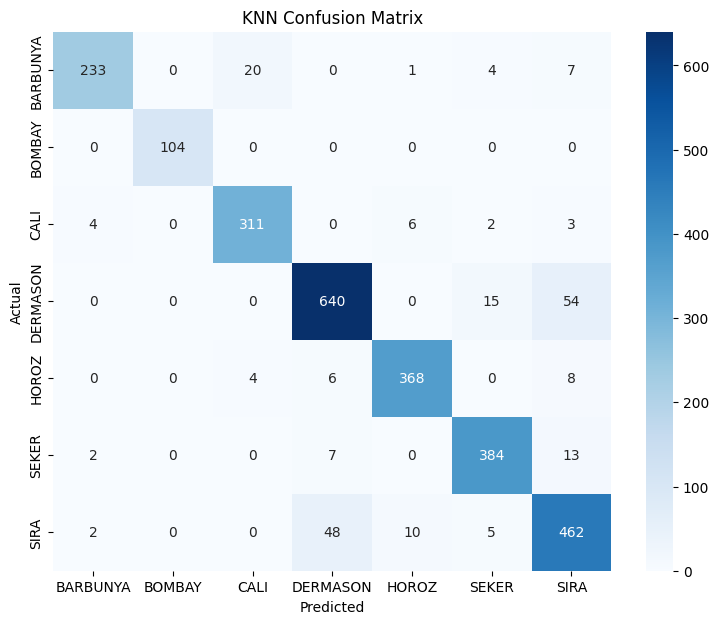

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_knn.classes_,
    yticklabels=best_knn.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.savefig(
    FIGURES_DIR / "knn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 08. Phân tích kết quả thực nghiệm KNN

Mô hình KNN sau khi tối ưu bằng GridSearchCV đạt Accuracy = 0.9188 và F1-macro = 0.9323 trên tập Test. Kết quả cho thấy mô hình có khả năng phân loại tương đối tốt đối với 7 loại hạt đậu.

**Phân tích Classification Report:**

- **BOMBAY:** F1-score đạt 1.0000, mô hình phân loại chính xác toàn bộ mẫu trong tập Test.
- **HOROZ:** F1-score khoảng 0.9546, cho thấy khả năng nhận diện tốt.
- **SIRA:** F1-score khoảng 0.8603, thấp nhất trong 7 lớp, cho thấy đây là lớp còn gặp khó khăn khi phân loại.
- **DERMASON:** F1-score khoảng 0.91, mô hình nhận diện khá tốt nhưng vẫn có sự nhầm lẫn với lớp SIRA.

**Phân tích Confusion Matrix:**

Ma trận nhầm lẫn cho thấy phần lớn mẫu được phân loại chính xác nằm trên đường chéo chính. Tuy nhiên, sự nhầm lẫn đáng chú ý nhất xuất hiện giữa hai lớp DERMASON và SIRA:

- 54 mẫu DERMASON bị dự đoán thành SIRA.
- 48 mẫu SIRA bị dự đoán thành DERMASON.

Nguyên nhân có thể do hai loại hạt có một số đặc trưng hình học tương đồng, khiến KNN khó phân biệt trong không gian đặc trưng.

**Kết luận:**

KNN đạt hiệu quả phân loại tốt với F1-macro 0.9323. Tuy nhiên, mô hình vẫn gặp khó khăn khi phân biệt DERMASON và SIRA. Vì vậy, cần tiếp tục thực nghiệm mô hình SVM để so sánh hiệu quả phân loại trên cùng tập dữ liệu và cùng phương pháp chia Train/Test.

## 09. SVM

**Nhiệm vụ:** Pipeline(StandardScaler, SVC), GridSearchCV thử kernel/C/gamma phù hợp; ghi kết quả CV và phân tích.





## Cơ sở lý thuyết Support Vector Machine (SVM)

### 1. Tổng quan về SVM

Support Vector Machine (SVM) là thuật toán học máy có giám sát, được sử dụng cho bài toán phân loại và hồi quy. Trong bài toán phân loại, SVM tìm một siêu phẳng (Hyperplane) tối ưu để phân tách các lớp dữ liệu.

Mục tiêu của SVM là tìm ranh giới phân loại sao cho khoảng cách từ siêu phẳng đến các điểm dữ liệu gần nhất của mỗi lớp là lớn nhất.

### 2. Siêu phẳng phân tách (Hyperplane)

Siêu phẳng là ranh giới dùng để phân chia dữ liệu thành các lớp khác nhau.

Phương trình tổng quát:

\[
w^T x + b = 0
\]

Trong đó:
- \(w\): vector trọng số.
- \(x\): vector đặc trưng đầu vào.
- \(b\): hệ số điều chỉnh vị trí siêu phẳng.

### 3. Margin và Support Vectors

- **Margin:** Khoảng cách giữa siêu phẳng phân tách và các điểm dữ liệu gần nhất thuộc các lớp.
- **Support Vectors:** Những điểm dữ liệu nằm gần ranh giới phân loại nhất, có vai trò quyết định vị trí của siêu phẳng.

SVM cố gắng tối đa hóa Margin nhằm tăng khả năng tổng quát hóa của mô hình trên dữ liệu mới.

### 4. Kernel Trick và RBF Kernel

Đối với dữ liệu không thể phân tách tuyến tính, SVM sử dụng Kernel Trick để xử lý quan hệ phi tuyến mà không cần tính toán trực tiếp phép biến đổi dữ liệu sang không gian nhiều chiều.

Trong thực nghiệm này, nhóm sử dụng RBF (Radial Basis Function) Kernel.

Hàm RBF được biểu diễn:

\[
K(x_i,x_j)=\exp(-\gamma \|x_i-x_j\|^2)
\]

Trong đó:
- \(x_i,x_j\): Hai vector dữ liệu.
- \(\gamma\): Tham số điều chỉnh phạm vi ảnh hưởng của từng điểm dữ liệu.

### 5. Ý nghĩa tham số C và Gamma

**Tham số C:**

- C lớn: Phạt mạnh các lỗi phân loại trên tập huấn luyện, mô hình cố gắng phân loại chính xác hơn nhưng có thể dễ bị overfitting.
- C nhỏ: Cho phép nhiều lỗi hơn, tạo biên phân tách mềm hơn và có thể tăng khả năng tổng quát hóa.

**Tham số Gamma:**

- Gamma lớn: Phạm vi ảnh hưởng của mỗi điểm dữ liệu nhỏ, ranh giới phân loại có thể phức tạp hơn.
- Gamma nhỏ: Phạm vi ảnh hưởng rộng hơn, ranh giới phân loại thường mượt hơn.

### 6. Lý do lựa chọn SVM với RBF Kernel

Dry Bean Dataset có 16 đặc trưng hình học và 7 lớp phân loại. Quan hệ giữa các đặc trưng và nhãn có thể không tuyến tính.

Do đó, nhóm lựa chọn SVM với RBF Kernel để có thể mô hình hóa ranh giới phân loại phi tuyến.

Nhóm sử dụng StandardScaler để chuẩn hóa đặc trưng và GridSearchCV kết hợp Stratified 10-Fold Cross Validation để tìm bộ tham số tối ưu theo tiêu chí F1-macro.

### 7. Tham số tối ưu trong thực nghiệm

Kết quả thực nghiệm của mô hình SVM:

- Kernel: RBF.
- C: 10.
- Gamma: scale.
- Best CV F1-macro: 0.9441.

Các tham số trên được lựa chọn thông qua quá trình GridSearchCV trên tập Train. Tập Test chỉ được sử dụng để đánh giá hiệu quả cuối cùng của mô hình.


In [13]:
# 09. SVM - Support Vector Machine

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Xây dựng Pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

# 2. Lưới tham số
param_grid_svm = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.1, 1, 10, 100]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1]
    }
]

# 3. Stratified 10-Fold Cross Validation
cv_svm = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV
grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring='f1_macro',
    cv=cv_svm,
    n_jobs=-1,
    verbose=1
)

print("Đã thiết lập Pipeline SVM và GridSearchCV.")


Đã thiết lập Pipeline SVM và GridSearchCV.


In [14]:
# 5. Huấn luyện trên tập Train
grid_svm.fit(X_train, y_train)

# 6. Lấy mô hình tốt nhất
best_svm = grid_svm.best_estimator_

print("===== KẾT QUẢ TỐI ƯU SVM =====")
print("Best parameters:", grid_svm.best_params_)
print("Best CV F1-macro:", round(grid_svm.best_score_, 4))

Fitting 10 folds for each of 20 candidates, totalling 200 fits
===== KẾT QUẢ TỐI ƯU SVM =====
Best parameters: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Best CV F1-macro: 0.9441


===== ĐÁNH GIÁ SVM TRÊN TEST =====
Accuracy: 0.9243
F1-macro: 0.9361

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.95       406
        SIRA       0.87      0.86      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



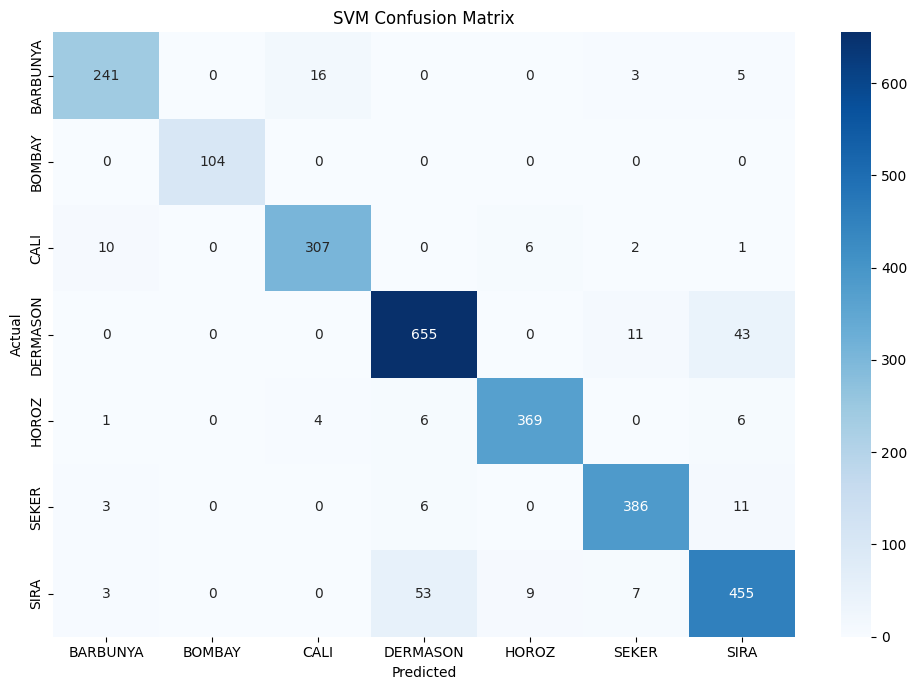

In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Dự đoán trên tập Test
y_pred_svm = best_svm.predict(X_test)

# Đánh giá mô hình
print("===== ĐÁNH GIÁ SVM TRÊN TEST =====")
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print("F1-macro:", round(f1_score(y_test, y_pred_svm, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_svm.classes_,
    yticklabels=best_svm.classes_
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [16]:
# Lưu kết quả tổng hợp SVM
svm_results = pd.DataFrame([{
    "Best_Params": str(grid_svm.best_params_),
    "Best_CV_F1_Macro": grid_svm.best_score_,
    "Test_Accuracy": accuracy_score(y_test, y_pred_svm),
    "Test_F1_Macro": f1_score(
        y_test, y_pred_svm, average="macro"
    )
}])

TABLES_DIR.mkdir(parents=True, exist_ok=True)

svm_results.to_csv(
    TABLES_DIR / "svm_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả SVM thành công!")
display(svm_results)

Đã lưu kết quả SVM thành công!


,Best_Params,Best_CV_F1_Macro,Test_Accuracy,Test_F1_Macro
0,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.944081,0.924348,0.936087


In [17]:
svm_report = classification_report(
    y_test,
    y_pred_svm,
    output_dict=True
)

svm_report_df = pd.DataFrame(svm_report).transpose()

svm_report_df.to_csv(
    TABLES_DIR / "svm_classification_report.csv",
    encoding="utf-8-sig"
)

print("Đã lưu Classification Report SVM!")
display(svm_report_df)

Đã lưu Classification Report SVM!


,precision,recall,f1-score,support
BARBUNYA,0.934109,0.909434,0.921606,265.000000
BOMBAY,1.000000,1.000000,1.000000,104.000000
CALI,0.938838,0.941718,0.940276,326.000000
DERMASON,0.909722,0.923836,0.916725,709.000000
HOROZ,0.960938,0.955959,0.958442,386.000000
SEKER,0.943765,0.950739,0.947239,406.000000
SIRA,0.873321,0.863378,0.868321,527.000000
accuracy,0.924348,0.924348,0.924348,0.924348
macro avg,0.937242,0.935009,0.936087,2723.000000
weighted avg,0.924320,0.924348,0.924295,2723.000000


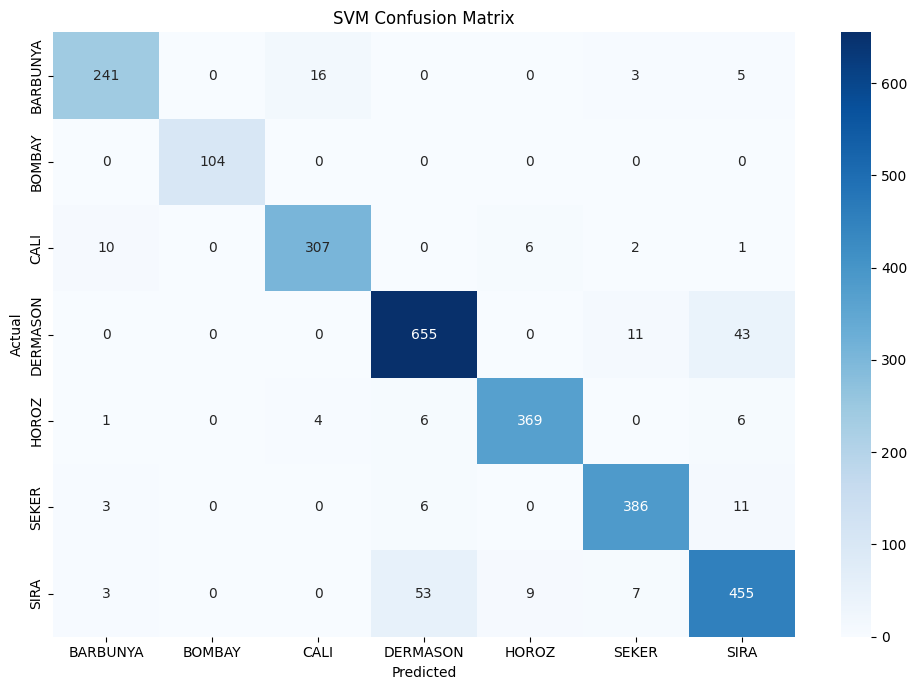

Đã lưu Confusion Matrix SVM!


In [18]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_svm.classes_,
    yticklabels=best_svm.classes_
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu Confusion Matrix SVM!")

In [20]:

comparison = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "CV F1-macro (10-Fold)": [
        grid_knn.best_score_,
        grid_svm.best_score_
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Test F1-macro": [
        f1_score(y_test, y_pred_knn, average="macro"),
        f1_score(y_test, y_pred_svm, average="macro")
    ]
})

display(comparison.round(4))

# Lựa chọn mô hình dựa trên CV F1-macro
best_model = comparison.loc[
    comparison["CV F1-macro (10-Fold)"].idxmax(),
    "Model"
]

print("Mô hình được lựa chọn:", best_model)


,Model,CV F1-macro (10-Fold),Test Accuracy,Test F1-macro
0,KNN,0.9379,0.9188,0.9323
1,SVM,0.9441,0.9243,0.9361


Mô hình được lựa chọn: SVM



## 9.1. Nhận xét kết quả

Dựa trên kết quả thực nghiệm, SVM đạt CV F1-macro 10-Fold là 0.9441, cao hơn KNN với 0.9379. Điều này cho thấy SVM có khả năng tổng quát hóa tốt hơn trên dữ liệu huấn luyện thông qua quá trình Cross Validation.

Trên tập Test, SVM tiếp tục đạt kết quả cao hơn KNN:
- Test Accuracy: 0.9243 so với 0.9188.
- Test F1-macro: 0.9361 so với 0.9323.

Kết quả cho thấy SVM có hiệu suất tốt hơn KNN trong thực nghiệm này. Đáng chú ý, thứ hạng của hai mô hình trên tập Test cũng phù hợp với kết quả Cross Validation.


## 9.2. Kết luận

Dựa trên kết quả Cross Validation 10-Fold, SVM được lựa chọn là mô hình tốt hơn giữa hai thuật toán được thực nghiệm, với CV F1-macro đạt 0.9441, cao hơn KNN (0.9379).

Kết quả đánh giá cuối cùng trên tập Test cũng cho thấy SVM đạt Accuracy = 0.9243 và F1-macro = 0.9361.

Như vậy, SVM là mô hình được lựa chọn cho bài toán phân loại Dry Bean Dataset trong phạm vi thực nghiệm này. Kết luận được đưa ra dựa trên kết quả Cross Validation, trong khi tập Test được sử dụng để xác nhận hiệu suất cuối cùng.



## 07/09. Bàn giao

**Nhiệm vụ:** Bàn giao bảng tham số tối ưu, F1 trung bình, độ lệch (nếu có), hình và notebook cho thong và len.



## 1. Mục tiêu

Tổng hợp kết quả thực nghiệm KNN và SVM để bàn giao cho các thành viên phụ trách tổng hợp báo cáo và hoàn thiện dự án.

## 2. Kết quả bàn giao

| Nội dung | KNN | SVM |
|---|---:|---:|
| CV F1-macro (10-Fold) | 0.9379 | 0.9441 |
| Test Accuracy | 0.9188 | 0.9243 |
| Test F1-macro | 0.9323 | 0.9361 |

## 3. Nội dung bàn giao

- Notebook thực nghiệm KNN và SVM.
- Bộ tham số tối ưu (best_params_).
- Kết quả Cross Validation 10-Fold.
- Classification Report.
- Confusion Matrix.
- Các biểu đồ và bảng kết quả thực nghiệm.

## 4. Nhận xét

SVM đạt CV F1-macro và các chỉ số đánh giá trên tập Test cao hơn KNN trong thực nghiệm này.

Kết quả được bàn giao để nhóm sử dụng trong quá trình tổng hợp, so sánh và hoàn thiện báo cáo.


## Bàn giao và kiểm tra

- [ ] Có giải thích thuật toán/kiến thức từng phần.
- [ ] Code chạy được từ đầu đến cuối (Restart & Run All).
- [ ] Không có số liệu hoặc điểm đánh giá được ghi cứng.
- [ ] Có bảng/biểu đồ và nhận xét từ kết quả thật.
- [ ] Đã push lên nhánh cá nhân và tạo Pull Request để trưởng nhóm xem xét (khi nhóm bắt đầu làm).
